# Numerical experiments — reproduction notebook

This notebook reproduces the numerical experiments accompanying the paper.
It relies on two companion modules:

- `utils.py` — the iterative policy algorithm and helper functions;
- `simulation.py` — the parallel Monte-Carlo pipeline (not needed here).

Each section below corresponds to a scenario studied in the paper. Apart from
the LSAC dataset (see *Data* at the end), the notebook is self-contained.


## Setup

The notebook needs `numpy`, `pandas`, `matplotlib`, `cvxpy` and `tqdm`.
Running every section end-to-end takes a few minutes.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from tqdm import tqdm

from utils import (
    run_dynamics_iterations,
    lambda_test,
    generate_gradual_growth_dynamics,
    generate_random_transition,
    perturb_transition_matrix,
    split_distributions,
    tridiagonal_transition,
)

# Experiment sizes used throughout the notebook.
ITERS = 1000
NUM_SIMS = 100
NUM_PERTURB_SIMS = 10
PERTURB_ITERS = 300
NUM_RAND_SIMS = 20

# Consistent colors for the penalty weights used in later sections.
LAMB_COLORS = {0.03: "tab:blue", 0.05: "tab:orange"}


### Example: the fairness penalty can hurt (Theorem 3)



In [2]:
D = 3
Y = np.array([-2, -1, 2])
a_size = 0.5

T1 = np.array([
    [0.8, 0.1, 0.1],
    [0.8, 0.1, 0.1],
    [0.1, 0.1, 0.8],
])
T2 = np.array([
    [0.8, 0.1, 0.1],
    [0.1, 0.1, 0.8],
    [0.1, 0.1, 0.8],
])

a_init = np.array([0.3, 0.1, 0.6])
b_init = np.array([0.5, 0.1, 0.4])


100%|██████████| 20/20 [00:00<00:00, 367.03it/s]


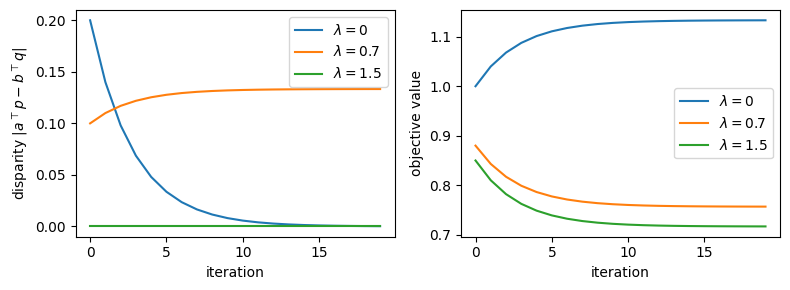

In [3]:
iters = 20
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

for lamb in [0, 0.7, 1.5]:
    result = run_dynamics_iterations(
        Y, T1, T2, a_init, b_init, cp.abs,
        lamb=lamb, a_size=a_size, iters=iters,
    )
    axes[0].plot(np.arange(iters), result.delta_hist, label=rf"$\lambda={lamb}$")
    axes[1].plot(np.arange(iters), result.value_hist, label=rf"$\lambda={lamb}$")

axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"disparity $|a^\top p - b^\top q|$")
axes[0].legend()
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("objective value")
axes[1].legend()
fig.tight_layout()


## LSAC dataset

The empirical experiments use the Law School Admission Council (LSAC) bar
passage prediction data. The file `lsac/bar_pass_prediction.csv` must be
placed in the `lsac/` directory (it is not redistributed here). We keep the
rows with complete `zfygpa`, `gpa`, `sex` and `race` fields.


In [2]:
df = pd.read_csv("lsac/bar_pass_prediction.csv")
df = df.dropna(subset=["zfygpa", "gpa", "sex", "race"])
df.shape


(21406, 39)

Race demographics

In [3]:
THRESHOLD = 2.95

a, b, a_size, Y = split_distributions(
    df,
    value_col="gpa",
    group_col="race",
    group_a=7,
    threshold=THRESHOLD,
)
print(f"{df.shape[0]} rows, {len(Y)} discretized GPA values, group share {a_size:.3f}")


21406 rows, 25 discretized GPA values, group share 0.837


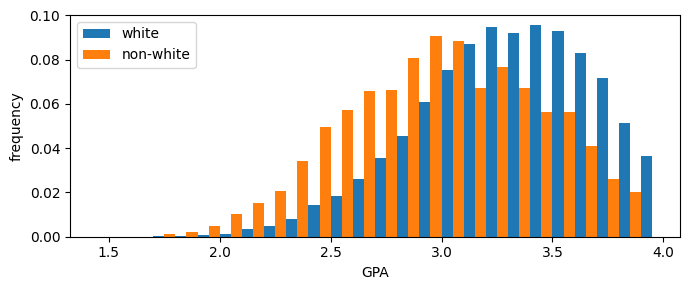

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
x = Y + THRESHOLD
width = 0.05

ax.bar(x + width / 2, a, width, label="white")
ax.bar(x - width / 2, b, width, label="non-white")

ax.set_xlabel("GPA")
ax.set_ylabel("frequency")
ax.legend()
fig.tight_layout()


Sex demographics

In [5]:
THRESHOLD = 2.95

a, b, a_size, Y = split_distributions(
    df,
    value_col="gpa",
    group_col="sex",
    group_a=1.0,
    threshold=THRESHOLD,
)
print(f"{df.shape[0]} rows, {len(Y)} discretized GPA values, group share {a_size:.3f}")


21406 rows, 25 discretized GPA values, group share 0.436


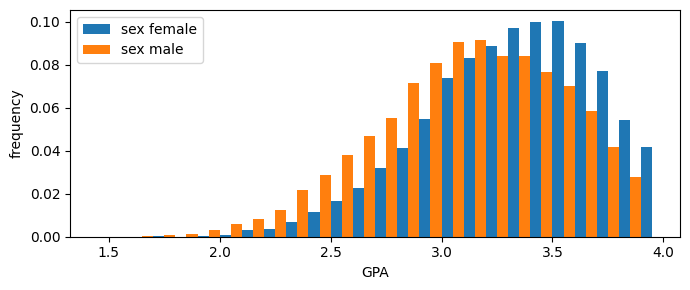

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
x = Y + THRESHOLD
width = 0.05

ax.bar(x + width / 2, a, width, label="female")
ax.bar(x - width / 2, b, width, label="male")

ax.set_xlabel("GPA")
ax.set_ylabel("frequency")
ax.legend()
fig.tight_layout()


## Scenario: effectiveness of the disparity penalty


100%|██████████| 100/100 [00:00<00:00, 339.64it/s]


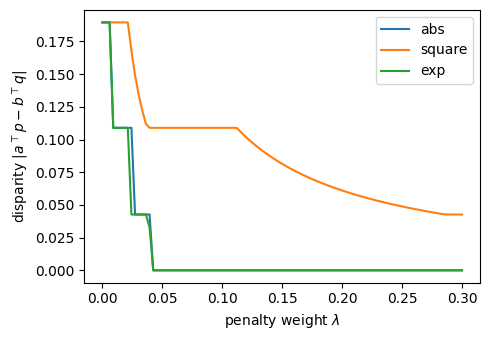

In [15]:
THRESHOLD = 2.95

a, b, a_size, Y = split_distributions(
    df,
    value_col="gpa",
    group_col="race",
    group_a=7,
    threshold=THRESHOLD,
)

lambs = np.linspace(0, 0.3, 100)
penalties = {"abs": cp.abs, "square": cp.square, "exp": cp.exp}

fig, ax = plt.subplots(figsize=(5, 3.5))
for name, penalty in penalties.items():
    _, ps, qs = lambda_test(Y, a, b, a_size, penalty, lambs=lambs)
    ax.plot(lambs, np.abs(ps - qs), label=name)

ax.set_xlabel(r"penalty weight $\lambda$")
ax.set_ylabel(r"disparity $|a^\top p - b^\top q|$")
ax.legend()
fig.tight_layout()


100%|██████████| 100/100 [00:00<00:00, 335.02it/s]


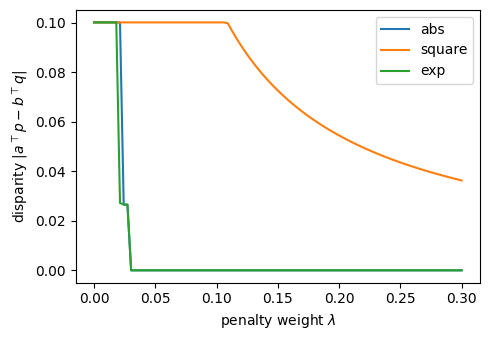

In [16]:
THRESHOLD = 2.95

a, b, a_size, Y = split_distributions(
    df,
    value_col="gpa",
    group_col="sex",
    group_a=1.0,
    threshold=THRESHOLD,
)

lambs = np.linspace(0, 0.3, 100)
penalties = {"abs": cp.abs, "square": cp.square, "exp": cp.exp}

fig, ax = plt.subplots(figsize=(5, 3.5))
for name, penalty in penalties.items():
    _, ps, qs = lambda_test(Y, a, b, a_size, penalty, lambs=lambs)
    ax.plot(lambs, np.abs(ps - qs), label=name)

ax.set_xlabel(r"penalty weight $\lambda$")
ax.set_ylabel(r"disparity $|a^\top p - b^\top q|$")
ax.legend()
fig.tight_layout()


## Scenario: dynamics with growth advantage


In [19]:
growth_tv = []
for _ in tqdm(range(NUM_SIMS), desc="growth advantage"):
    T1, T2 = generate_gradual_growth_dynamics(len(Y))
    lamb = np.random.uniform(0, 1)
    result = run_dynamics_iterations(
        Y, T1, T2, a, b, cp.abs,
        lamb=lamb, a_size=a_size, iters=ITERS, disable=True,
    )
    growth_tv.append(result.tv)


growth advantage: 100%|██████████| 100/100 [04:28<00:00,  2.68s/it]


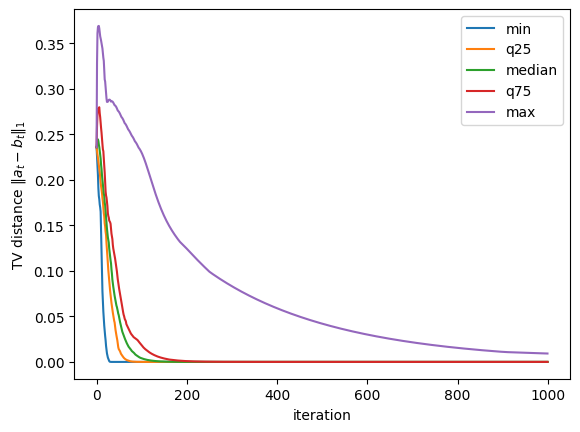

In [20]:
tv_quantiles = (
    pd.DataFrame(growth_tv)
    .quantile([0, 0.25, 0.5, 0.75, 1])
    .transpose()
)
tv_quantiles.columns = ["min", "q25", "median", "q75", "max"]

ax = tv_quantiles.plot()
ax.set_xlabel("iteration")
ax.set_ylabel(r"TV distance $\|a_t - b_t\|_1$");


## Scenario: persistent disparity


In [10]:
n = len(Y)

# Down/up jump probabilities for the first group: a bottleneck band of high
# persistence in the middle of the GPA range.
d1_down = np.full(n, 0.2)
d1_down[11:17] = 0.7
d1_up = np.full(n, 0.2)

# Down/up jump probabilities for the second group.
d2_down = np.full(n, 0.2)
d2_up = np.full(n, 0.2)
d2_up[11:18] = 0.7

T1 = tridiagonal_transition(d1_down, d1_up)
T2 = tridiagonal_transition(d2_down, d2_up)


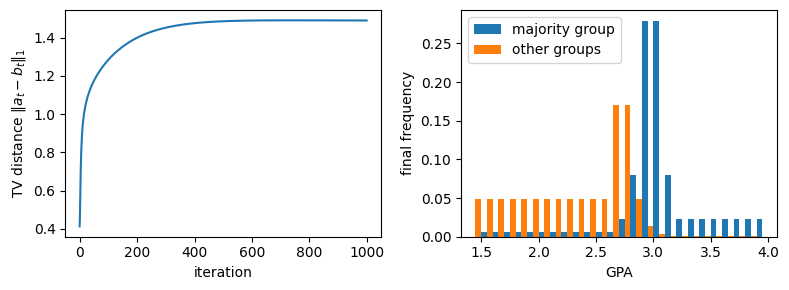

In [11]:
persist_result = run_dynamics_iterations(
    Y, T1, T2, a, b, cp.abs,
    lamb=0.03, a_size=a_size, iters=ITERS,
)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].plot(persist_result.tv)
axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"TV distance $\|a_t - b_t\|_1$")

x = Y + THRESHOLD
width = 0.05
axes[1].bar(x + width / 2, persist_result.a_hist[-1], width, label="majority group")
axes[1].bar(x - width / 2, persist_result.b_hist[-1], width, label="other groups")
axes[1].set_xlabel("GPA")
axes[1].set_ylabel("final frequency")
axes[1].legend()
fig.tight_layout()


## Scenario: robustness to perturbed dynamics



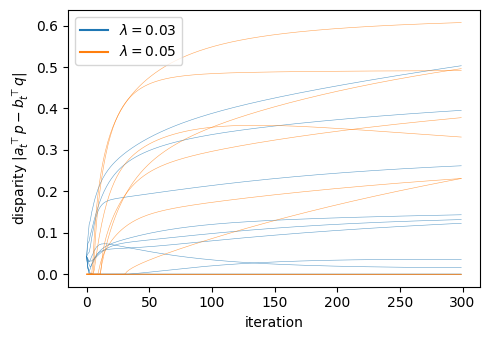

In [12]:
perturb_deltas = {}
for lamb in [0.03, 0.05]:
    deltas = []
    for _ in range(NUM_PERTURB_SIMS):
        Tp1 = perturb_transition_matrix(T1, scale=0.3)
        Tp2 = perturb_transition_matrix(T2, scale=0.3)
        result = run_dynamics_iterations(
            Y, Tp1, Tp2, a, b, cp.abs,
            lamb=lamb, a_size=a_size, iters=PERTURB_ITERS, disable=True,
        )
        deltas.append(result.delta_hist)
    perturb_deltas[lamb] = deltas

fig, ax = plt.subplots(figsize=(5, 3.5))
for lamb, deltas in perturb_deltas.items():
    for delta in deltas:
        ax.plot(
            np.arange(PERTURB_ITERS), delta,
            color=LAMB_COLORS[lamb], linewidth=0.4, alpha=0.7,
        )
    ax.plot([], [], color=LAMB_COLORS[lamb], label=rf"$\lambda={lamb}$")

ax.set_xlabel("iteration")
ax.set_ylabel(r"disparity $|a_t^\top p - b_t^\top q|$")
ax.legend()
fig.tight_layout()


## Scenario: random dynamics


In [13]:
rand_delta = {}
for lamb in [0.03, 0.05]:
    deltas = []
    for _ in tqdm(range(NUM_RAND_SIMS), desc=f"random dynamics, lambda={lamb}"):
        T1 = generate_random_transition(len(Y))
        T2 = generate_random_transition(len(Y))
        result = run_dynamics_iterations(
            Y, T1, T2, a, b, cp.abs,
            lamb=lamb, a_size=a_size, iters=ITERS, disable=True,
        )
        deltas.append(result.delta_hist)
    rand_delta[lamb] = deltas


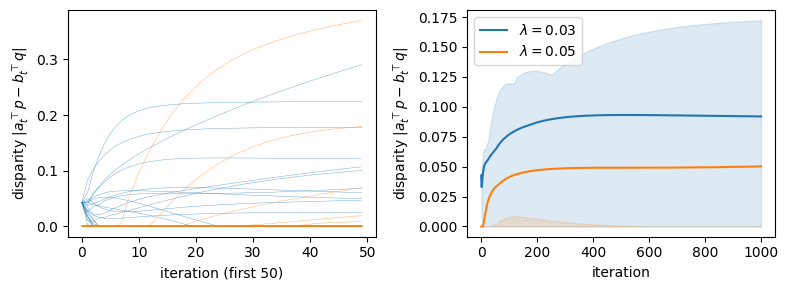

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

for lamb, deltas in rand_delta.items():
    for delta in deltas:
        axes[0].plot(
            np.arange(50), delta[:50],
            color=LAMB_COLORS[lamb], linewidth=0.3, alpha=0.7,
        )
    axes[1].plot(
        np.arange(ITERS), np.mean(deltas, axis=0),
        color=LAMB_COLORS[lamb], label=rf"$\lambda={lamb}$",
    )
    axes[1].fill_between(
        np.arange(ITERS),
        np.quantile(deltas, 0.25, axis=0),
        np.quantile(deltas, 0.75, axis=0),
        color=LAMB_COLORS[lamb], alpha=0.15,
    )

axes[0].set_xlabel("iteration (first 50)")
axes[0].set_ylabel(r"disparity $|a_t^\top p - b_t^\top q|$")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel(r"disparity $|a_t^\top p - b_t^\top q|$")
axes[1].legend()
fig.tight_layout()


## Notes

- **Runtime**: the growth-advantage and random-dynamics sections run a few
  hundred simulations of 1000 iterations each; expect a few minutes in total.
- **Scripted pipeline**: the non-interactive version of the random-dynamics
  experiment is `simulation.py`; its outputs are summarized by
  `process_random_tran_band.py`.
- **Dependencies**: `numpy`, `pandas`, `scipy`, `matplotlib`, `cvxpy`,
  `tqdm`.

### Data

The LSAC bar passage prediction dataset is publicly available (e.g. from
Kaggle). Place `bar_pass_prediction.csv` under `lsac/` before running this
notebook.
